# 05 · LLM-generated Neutral training data

Neutral is 2.3% of the classifier's training pairs (455 of about 20,000), and no reweighting or resampling method in notebook 02 raised Neutral F1 above about 0.45. This notebook adds new, different Neutral examples written by an LLM.

1. **Generation.** Qwen2.5-7B-Instruct receives a real aspect and category from a domain and four real Neutral sentences from that domain, and writes a new sentence with a neutral opinion about the aspect (temperature 0.9, 3,000 candidates).
2. **Format filters.** The aspect must appear verbatim, 5–60 words, no duplicates, no copies of training sentences; text is tokenised like the dataset.
3. **Verification.** The same model, in a separate prompt that does not reveal the request, labels the sentiment towards the aspect; only sentences labelled neutral are kept.
4. **Training.** DeBERTa-v3-small with class weights (the notebook 02 recipe), trained on the real pairs plus the verified synthetic pairs (`augment`) or plus every format-valid synthetic pair (`augment_noverify`), seeds 42, 153 and 650. The test set is unchanged and fully human-annotated.

In [1]:
PROJECT_DIR = "/content/drive/MyDrive/aspect-insight"

In [2]:
import os, sys
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    PROJECT_DIR = os.path.abspath("..")
os.chdir(PROJECT_DIR)
sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
print(os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/aspect-insight


In [3]:
!pip -q install -r requirements.txt
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
NVIDIA L4, 23034 MiB


## Generation and verification

In [4]:
!python scripts/generate_neutral.py

/content/drive/MyDrive/aspect-insight/data/processed/synthetic/neutral_pairs.jsonl already exists, skipped (use --force to regenerate)


In [5]:
from IPython.display import Image, Markdown, display

display(Markdown(open("data/processed/synthetic/generation_report.md", encoding="utf-8").read()))

# Synthetic Neutral pairs

Generator and verifier: `Qwen/Qwen2.5-7B-Instruct`, temperature 0.9, 4 real Neutral examples per request.

| Step | Sentences |
|---|---|
| generated | 3,000 |
| rejected: aspect missing | 178 |
| rejected: duplicate | 42 |
| rejected: not English | 227 |
| passed format filters | 2,553 |
| verified neutral | 1,705 |
| rejected by verifier | 848 |

| Domain | Real Neutral (train) | Synthetic, verified | Synthetic, format filters only |
|---|---|---|---|
| Books | 86 | 268 | 439 |
| Clothing | 46 | 165 | 311 |
| Hotel | 19 | 334 | 538 |
| Laptop | 220 | 392 | 555 |
| Restaurant | 84 | 546 | 710 |

## Examples (verified)

- *Restaurant*, aspect **atmosphere**: The atmosphere is just average , neither too cozy nor overly crowded .
- *Hotel*, aspect **snacks**: The selection of snacks was adequate , offering a few options for late - night munching .
- *Restaurant*, aspect **staff**: The staff seemed friendly enough , but there wasn ' t anything particularly noteworthy about their service .
- *Hotel*, aspect **street parking**: Street parking is available , though it can be a bit challenging during busy times .
- *Restaurant*, aspect **Customer service**: The customer service was standard , offering help when needed without being overly attentive .
- *Restaurant*, aspect **satay skewers**: The satay skewers were alright , with a decent blend of flavors , though not particularly outstanding .
- *Restaurant*, aspect **service**: The service was acceptable , neither particularly fast nor slow .
- *Restaurant*, aspect **service**: The service was adequate , neither particularly welcoming nor unfriendly .
- *Restaurant*, aspect **little dive bar**: The place is a little dive bar , so don ' t expect five - star conditions but it works for what it is .
- *Books*, aspect **Kathy**: Kathy was portrayed as a dedicated detective , which was an acceptable but unremarkable characterization .
- *Laptop*, aspect **email**: the email client works adequately , allowing me to send and receive messages without any issues .
- *Hotel*, aspect **apartment**: The apartment was adequately furnished , though not particularly distinctive .
- *Restaurant*, aspect **texture**: The texture of the pasta was al dente , as usual .
- *Clothing*, aspect **moc**: The moc boots have a traditional look , which is what I was expecting .
- *Books*, aspect **book**: The book provides a comprehensive overview of the subject without particularly standing out from others in its field .

## Examples rejected by the verifier

- *Laptop*, aspect **re - set button**, verifier: positive: the re - set button is located on the left side of the laptop , next to the battery compartment , and functions as expected .
- *Clothing*, aspect **style**, verifier: positive: The style is straightforward and classic , nothing too flashy but still noticeable .
- *Restaurant*, aspect **vegetable bao**, verifier: positive: The vegetable bao had just enough seasoning , neither overly salty nor bland .
- *Hotel*, aspect **hosts**, verifier: positive: The hosts were polite and available when needed , but nothing exceptional .
- *Books*, aspect **accounts**, verifier: negative: The accounts of the events , while detailed , do not offer any novel insights into the situation .
- *Hotel*, aspect **loft**, verifier: positive: The loft provided enough height for us to move around without bumping our heads , which was an acceptable feature .
- *Clothing*, aspect **size**, verifier: positive: The size was just right for my usual fit .
- *Laptop*, aspect **asus flip**, verifier: positive: asus flip comes with a standard backlit keyboard , which is convenient for typing in low - light conditions .


## Classifiers trained with synthetic Neutral data

In [6]:
!python scripts/train_classifiers.py --methods augment augment_noverify

Device: NVIDIA L4
Train 19,921 pairs (NEG 4,329 / NEU 455 / POS 15,137)
Dev   2,726 pairs (NEG 575 / NEU 68 / POS 2,083)
Test  5,479 pairs (NEG 1,197 / NEU 102 / POS 4,180)
[augment seed 42] already complete, skipped
[augment_noverify seed 42] already complete, skipped
[augment seed 153] already complete, skipped
[augment_noverify seed 153] training on 24,717 pairs (NEG 5,268 / NEU 3,174 / POS 16,275)
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Loading weights: 100% 102/102 [00:00<00:00, 16373.34it/s]
[transformers] DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     | 
----------------------------------------+------------+-
mask_predictions.classifier.bias        | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight

In [7]:
!python scripts/evaluate_classifiers.py

# Aspect-level sentiment: class-imbalance study

Test pairs: 5,479 (all five domains). Values are mean ± standard deviation over seeds.

| Method | Seeds | Accuracy | Macro-F1 | Neutral F1 | Conflicting acc | ECE | ECE after T-scaling (T) | Models | Train (min) | ms/pair |
|---|---|---|---|---|---|---|---|---|---|---|
| No handling | 3 | 0.929 ± 0.005 | 0.746 ± 0.011 | 0.410 ± 0.027 | 0.734 ± 0.003 | 0.050 | 0.021 (1.90) | 1 | 8.1 | 0.77 |
| Class weights | 3 | 0.930 ± 0.000 | 0.756 ± 0.007 | 0.438 ± 0.019 | 0.737 ± 0.015 | 0.053 | 0.024 (2.00) | 1 | 8.1 | 0.78 |
| Random oversampling | 3 | 0.928 ± 0.001 | 0.750 ± 0.004 | 0.426 ± 0.016 | 0.743 ± 0.005 | 0.056 | 0.032 (2.20) | 1 | 10.1 | 0.78 |
| Focal loss | 3 | 0.932 ± 0.002 | 0.759 ± 0.013 | 0.445 ± 0.035 | 0.742 ± 0.008 | 0.025 | 0.014 (0.89) | 1 | 8.1 | 0.78 |
| Balanced bagging (ensemble) | 3 | 0.911 ± 0.001 | 0.725 ± 0.002 | 0.381 ± 0.005 | 0.682 ± 0.008 | 0.038 | 0.012 (1.42) | 5 | 13.6 | 2.97 |
| Balanced bagging (one member) |

## Results

# Aspect-level sentiment: class-imbalance study

Test pairs: 5,479 (all five domains). Values are mean ± standard deviation over seeds.

| Method | Seeds | Accuracy | Macro-F1 | Neutral F1 | Conflicting acc | ECE | ECE after T-scaling (T) | Models | Train (min) | ms/pair |
|---|---|---|---|---|---|---|---|---|---|---|
| No handling | 3 | 0.929 ± 0.005 | 0.746 ± 0.011 | 0.410 ± 0.027 | 0.734 ± 0.003 | 0.050 | 0.021 (1.90) | 1 | 8.1 | 0.77 |
| Class weights | 3 | 0.930 ± 0.000 | 0.756 ± 0.007 | 0.438 ± 0.019 | 0.737 ± 0.015 | 0.053 | 0.024 (2.00) | 1 | 8.1 | 0.78 |
| Random oversampling | 3 | 0.928 ± 0.001 | 0.750 ± 0.004 | 0.426 ± 0.016 | 0.743 ± 0.005 | 0.056 | 0.032 (2.20) | 1 | 10.1 | 0.78 |
| Focal loss | 3 | 0.932 ± 0.002 | 0.759 ± 0.013 | 0.445 ± 0.035 | 0.742 ± 0.008 | 0.025 | 0.014 (0.89) | 1 | 8.1 | 0.78 |
| Balanced bagging (ensemble) | 3 | 0.911 ± 0.001 | 0.725 ± 0.002 | 0.381 ± 0.005 | 0.682 ± 0.008 | 0.038 | 0.012 (1.42) | 5 | 13.6 | 2.97 |
| Balanced bagging (one member) | 3 | 0.902 ± 0.007 | 0.709 ± 0.010 | 0.349 ± 0.021 | 0.668 ± 0.022 | 0.064 | 0.031 (1.72) | 1 | 2.7 | 0.59 |
| LLM synthetic Neutral (verified) | 3 | 0.925 ± 0.004 | 0.736 ± 0.018 | 0.388 ± 0.051 | 0.724 ± 0.016 | 0.054 | 0.022 (1.88) | 1 | 12.5 | 1.18 |
| LLM synthetic Neutral (not verified) | 3 | 0.924 ± 0.001 | 0.723 ± 0.003 | 0.346 ± 0.009 | 0.718 ± 0.008 | 0.054 | 0.021 (1.94) | 1 | 13.0 | 1.19 |

Temperature scaling: one temperature T per model, fitted on the Dev set by minimising negative log-likelihood; predictions are unchanged, only confidences.

## Macro-F1 per domain (mean over seeds)

| Method | Books | Clothing | Hotel | Laptop | Restaurant |
|---|---|---|---|---|---|
| No handling | 0.696 | 0.708 | 0.910 | 0.764 | 0.762 |
| Class weights | 0.712 | 0.682 | 0.931 | 0.768 | 0.780 |
| Random oversampling | 0.705 | 0.663 | 0.920 | 0.768 | 0.771 |
| Focal loss | 0.712 | 0.690 | 0.926 | 0.771 | 0.785 |
| Balanced bagging (ensemble) | 0.696 | 0.680 | 0.906 | 0.727 | 0.747 |
| Balanced bagging (one member) | 0.659 | 0.669 | 0.900 | 0.719 | 0.731 |
| LLM synthetic Neutral (verified) | 0.669 | 0.679 | 0.902 | 0.770 | 0.757 |
| LLM synthetic Neutral (not verified) | 0.647 | 0.654 | 0.915 | 0.759 | 0.757 |

## McNemar test against Class weights (per seed)

| Method | Seed | Only this method correct | Only class weights correct | p |
|---|---|---|---|---|
| LLM synthetic Neutral (verified) | 42 | 77 | 107 | 0.0322 |
| LLM synthetic Neutral (verified) | 153 | 84 | 87 | 0.879 |
| LLM synthetic Neutral (verified) | 650 | 71 | 120 | 0.000482 |
| LLM synthetic Neutral (not verified) | 42 | 69 | 104 | 0.00954 |
| LLM synthetic Neutral (not verified) | 153 | 83 | 107 | 0.0949 |
| LLM synthetic Neutral (not verified) | 650 | 80 | 115 | 0.0147 |
| Balanced bagging (ensemble) | 42 | 53 | 161 | 7.47e-14 |
| Balanced bagging (ensemble) | 153 | 90 | 194 | 6.39e-10 |
| Balanced bagging (ensemble) | 650 | 64 | 163 | 3.83e-11 |
| Balanced bagging (one member) | 42 | 71 | 204 | 4.49e-16 |
| Balanced bagging (one member) | 153 | 93 | 211 | 1.07e-11 |
| Balanced bagging (one member) | 650 | 74 | 226 | 4.72e-19 |
| Focal loss | 42 | 70 | 45 | 0.0248 |
| Focal loss | 153 | 74 | 69 | 0.738 |
| Focal loss | 650 | 62 | 64 | 0.929 |
| No handling | 42 | 87 | 80 | 0.643 |
| No handling | 153 | 82 | 72 | 0.468 |
| No handling | 650 | 63 | 100 | 0.00466 |
| Random oversampling | 42 | 89 | 105 | 0.281 |
| Random oversampling | 153 | 92 | 100 | 0.614 |
| Random oversampling | 650 | 75 | 89 | 0.31 |

## 95% bootstrap intervals (seed 42)

| Method | Macro-F1 | Neutral F1 |
|---|---|---|
| No handling | 0.740 [0.709, 0.769] | 0.390 [0.305, 0.471] |
| Class weights | 0.764 [0.736, 0.790] | 0.459 [0.373, 0.536] |
| Random oversampling | 0.754 [0.723, 0.782] | 0.443 [0.357, 0.523] |
| Focal loss | 0.773 [0.742, 0.803] | 0.484 [0.393, 0.564] |
| Balanced bagging (ensemble) | 0.724 [0.695, 0.750] | 0.380 [0.298, 0.455] |
| Balanced bagging (one member) | 0.718 [0.688, 0.749] | 0.379 [0.291, 0.465] |
| LLM synthetic Neutral (verified) | 0.742 [0.713, 0.772] | 0.411 [0.324, 0.493] |
| LLM synthetic Neutral (not verified) | 0.727 [0.700, 0.754] | 0.356 [0.278, 0.436] |


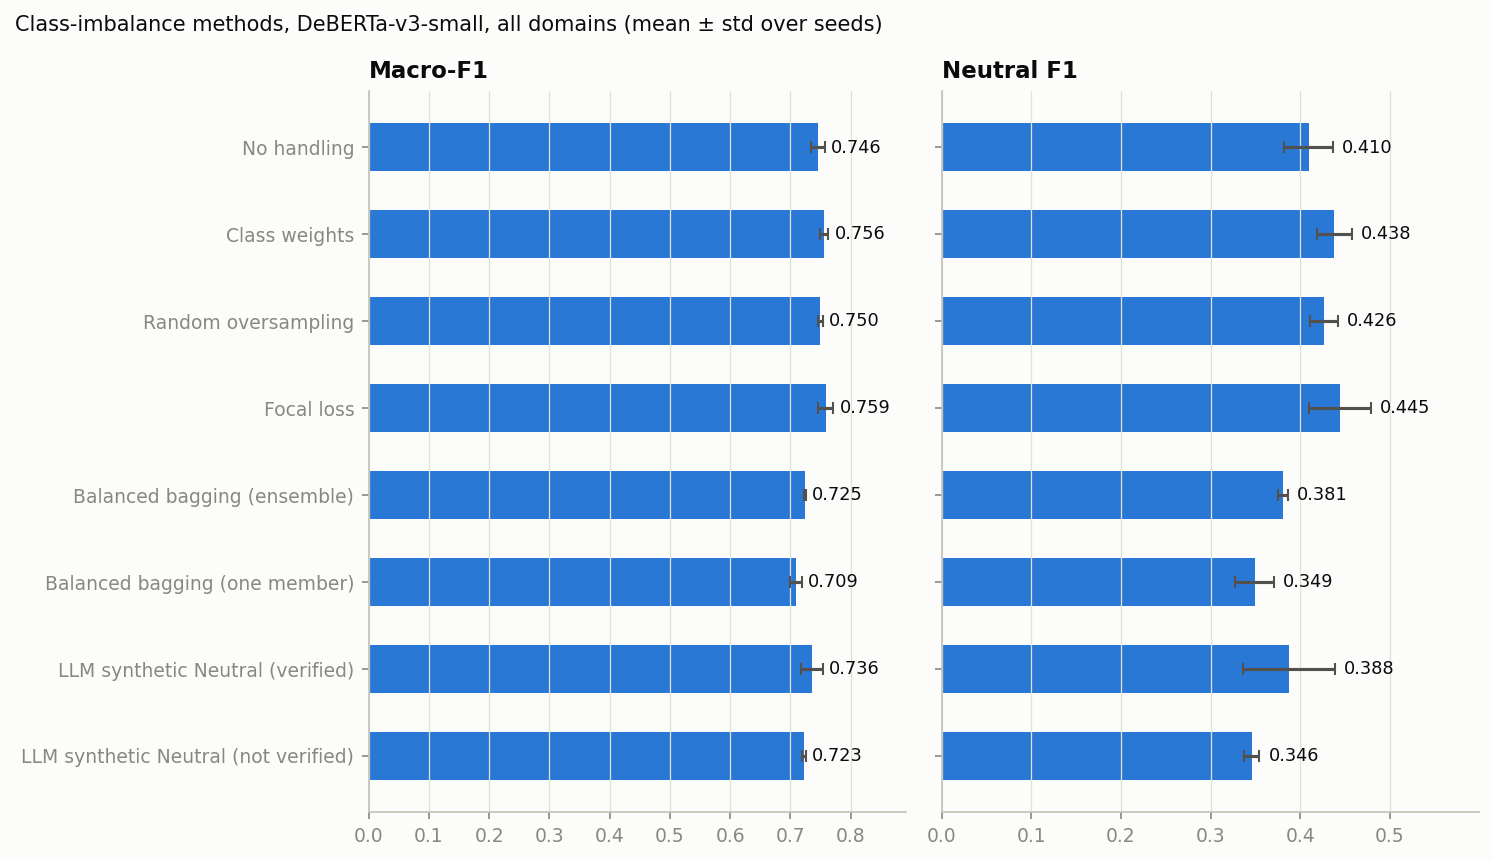

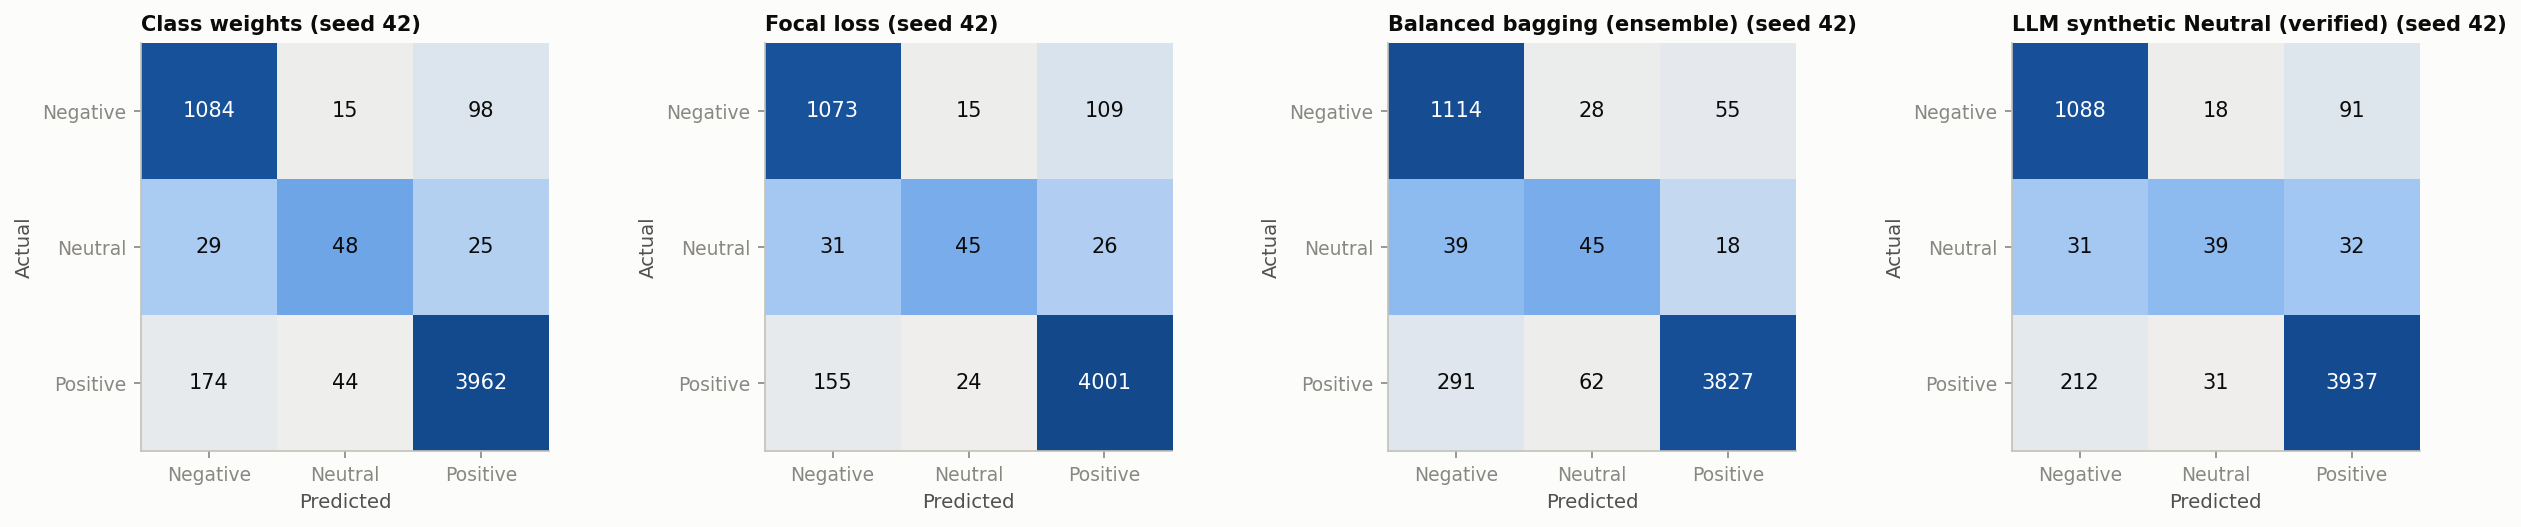

In [8]:
display(Markdown(open("outputs/results/classifiers/summary.md", encoding="utf-8").read()))
for name in ["imbalance_methods", "confusion_matrices"]:
    display(Image(f"outputs/results/classifiers/figures/{name}.png"))